<a href="https://colab.research.google.com/github/yashuu-2026/LLM_embeddibngs_learningphase/blob/main/Loan_Approval_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_score, recall_score

In [ ]:
df = pd.read_csv("/content/loan_data.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
print(df.shape,df.columns)
df.info()

(981, 13) Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 981 entries, 0 to 980
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            981 non-null    object 
 1   Gender             957 non-null    object 
 2   Married            978 non-null    object 
 3   Dependents         956 non-null    object 
 4   Education          981 non-null    object 
 5   Self_Employed      926 non-null    object 
 6   ApplicantIncome    981 non-null    int64  
 7   CoapplicantIncome  981 non-null    float64
 8   LoanAmount         954 non-null    float64
 9   Loan_Amount_Term   961 non-null    float64
 10  Credit_History     902 non-null    float64
 11  Property_Are

In [ ]:
df.dropna(inplace=True) #inplace --> save changes in same df
df.isnull().sum()

,0
Loan_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0


In [ ]:
df.drop_duplicates(inplace=True)

print("number of duplicated after dropping:", df.duplicated().sum())

number of duplicated after dropping: 0


In [ ]:
print(df.isnull().sum())
df.dropna()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


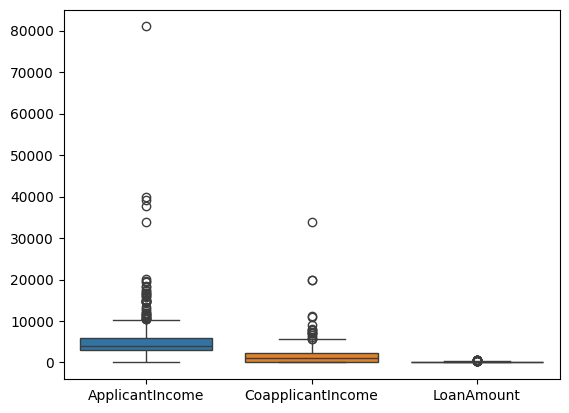

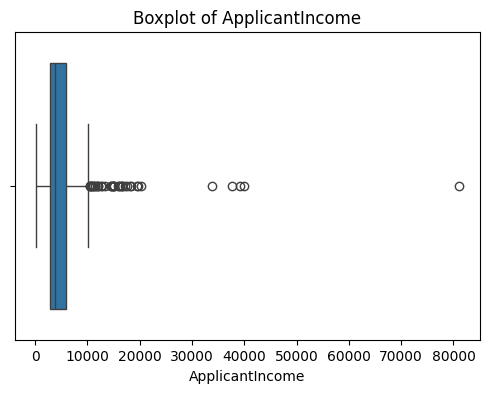

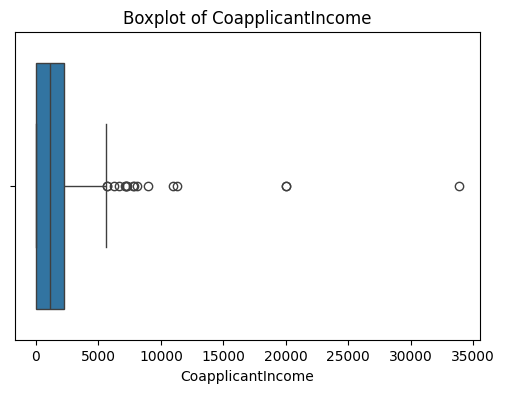

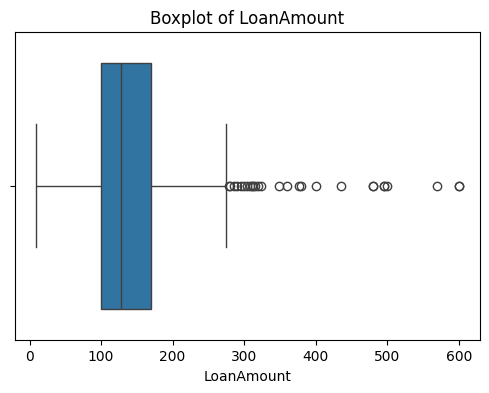

In [ ]:
sns.boxplot(data=df[["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]])
outliers_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]
for col in outliers_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])
  plt.title(f"Boxplot of {col}")
  plt.show()
#

In [ ]:
df.drop(columns=['Loan_ID'], inplace=True)
print("Columns after dropping Loan_ID:", df.columns)

Columns after dropping Loan_ID: Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')


In [ ]:
GE = LabelEncoder()
df["Gender_encoded"] = GE.fit_transform(df["Gender"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1


In [ ]:
ME = LabelEncoder()
df["Married_encoded"] = ME.fit_transform(df["Married"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1


In [ ]:
DE = LabelEncoder()
df["Dependents_encoded"] = DE.fit_transform(df["Dependents"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2


In [ ]:
EE = LabelEncoder()
df["Education_encoded"] = EE.fit_transform(df["Education"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0


In [ ]:
SE = LabelEncoder()
df["Self_Employed_encoded"] = SE.fit_transform(df["Self_Employed"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1


In [ ]:
PA = LabelEncoder()
df["Property_Area_encoded"] = PA.fit_transform(df["Property_Area"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded,Property_Area_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1,2
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0,2
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0,2
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1,2


In [ ]:
LS = LabelEncoder()
df["Loan_Status_encoded"] = LS.fit_transform(df["Loan_Status"])
df.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded,Property_Area_encoded,Loan_Status_encoded
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0,0,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1,2,1
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0,2,1
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0,2,1
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1,2,1


In [ ]:
X = df[["Gender_encoded","Married_encoded","Dependents_encoded","Education_encoded","Self_Employed_encoded","ApplicantIncome","CoapplicantIncome","LoanAmount",
    "Loan_Amount_Term","Credit_History","Property_Area_encoded"]]
y = df["Loan_Status_encoded"]
print("feature shape:", X.shape)
print("target shape:", y.shape)

feature shape: (480, 11)
target shape: (480,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("records for training:", len(x_train))
print("records for testing:", len(x_test))

records for training: 384
records for testing: 96


In [ ]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
scaler = StandardScaler()
x_train[num_cols] = scaler.fit_transform(x_train[num_cols])
x_test[num_cols] = scaler.transform(x_test[num_cols])

In [ ]:
Loan_Approval_model = LinearRegression()
Loan_Approval_model.fit(x_train, y_train)

LinearRegression()

In [ ]:
scale_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
scaler = StandardScaler()
x_train[scale_cols] = scaler.fit_transform(x_train[scale_cols])
x_test[scale_cols] = scaler.transform(x_test[scale_cols])
x_train.head()

,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_encoded
172,1,1,3,1,0,-0.310457,-0.590022,-0.809935,-2.397575,1.0,0
288,0,0,0,0,0,-0.211548,-0.590022,-0.370210,0.280345,1.0,1
607,1,1,2,1,0,-0.234057,-0.080986,0.172980,0.280345,1.0,0
55,1,1,2,0,0,-0.444196,-0.169012,-0.603005,0.280345,1.0,1
461,1,1,3,0,0,0.382558,-0.590022,-0.202079,-2.397575,1.0,2


In [ ]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)

y_pred_lr = lr.predict(x_test)
print(y_pred_lr)

[1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1]


In [ ]:
acc_lr = accuracy_score(y_test, y_pred_lr)
prec_lr = precision_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
print("Accuracy Score:", acc_lr)
print("Precision Score:", prec_lr)
print("Recall Score:", rec_lr)
print("F1 Score:", f1_lr)

Accuracy Score: 0.8229166666666666
Precision Score: 0.8
Recall Score: 1.0
F1 Score: 0.8888888888888888


Confusion Matrix:


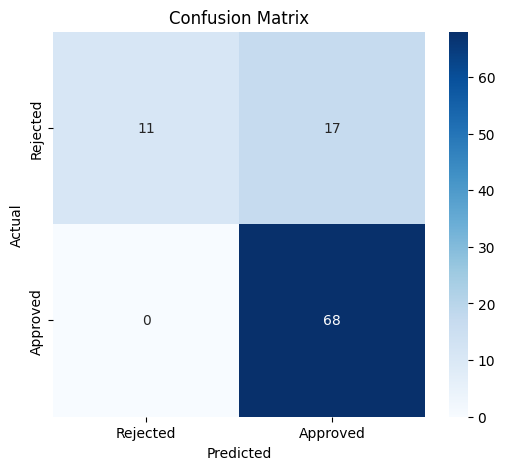

In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:")

plt.figure(figsize=(6, 5))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rejected", "Approved"],
            yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)

y_pred_dt = dt.predict(x_test)
print(y_pred_dt)

[1 1 1 0 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1
 1 0 0 1 1 0 0 1 0 0 1 1 0 1 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0
 1 1 1 1 0 1 1 1 0 1 1 0 1 1 0 1 0 1 1 1 1 1]


Accuracy Score: 0.75
Precision Score: 0.8142857142857143
Recall Score: 0.8382352941176471
F1 Score: 0.8260869565217391
Confusion Matrix:
 [[15 13]
 [11 57]]


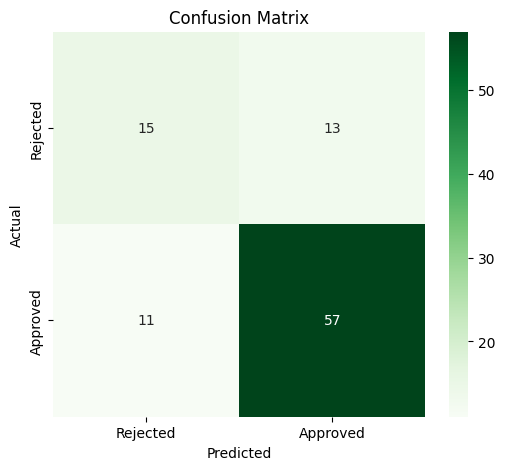

In [ ]:
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
print("Accuracy Score:", acc_dt)
print("Precision Score:", prec_dt)
print("Recall Score:", rec_dt)
print("F1 Score:", f1_dt)
cm_dt = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:\n",cm_dt)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Rejected", "Approved"],
            yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

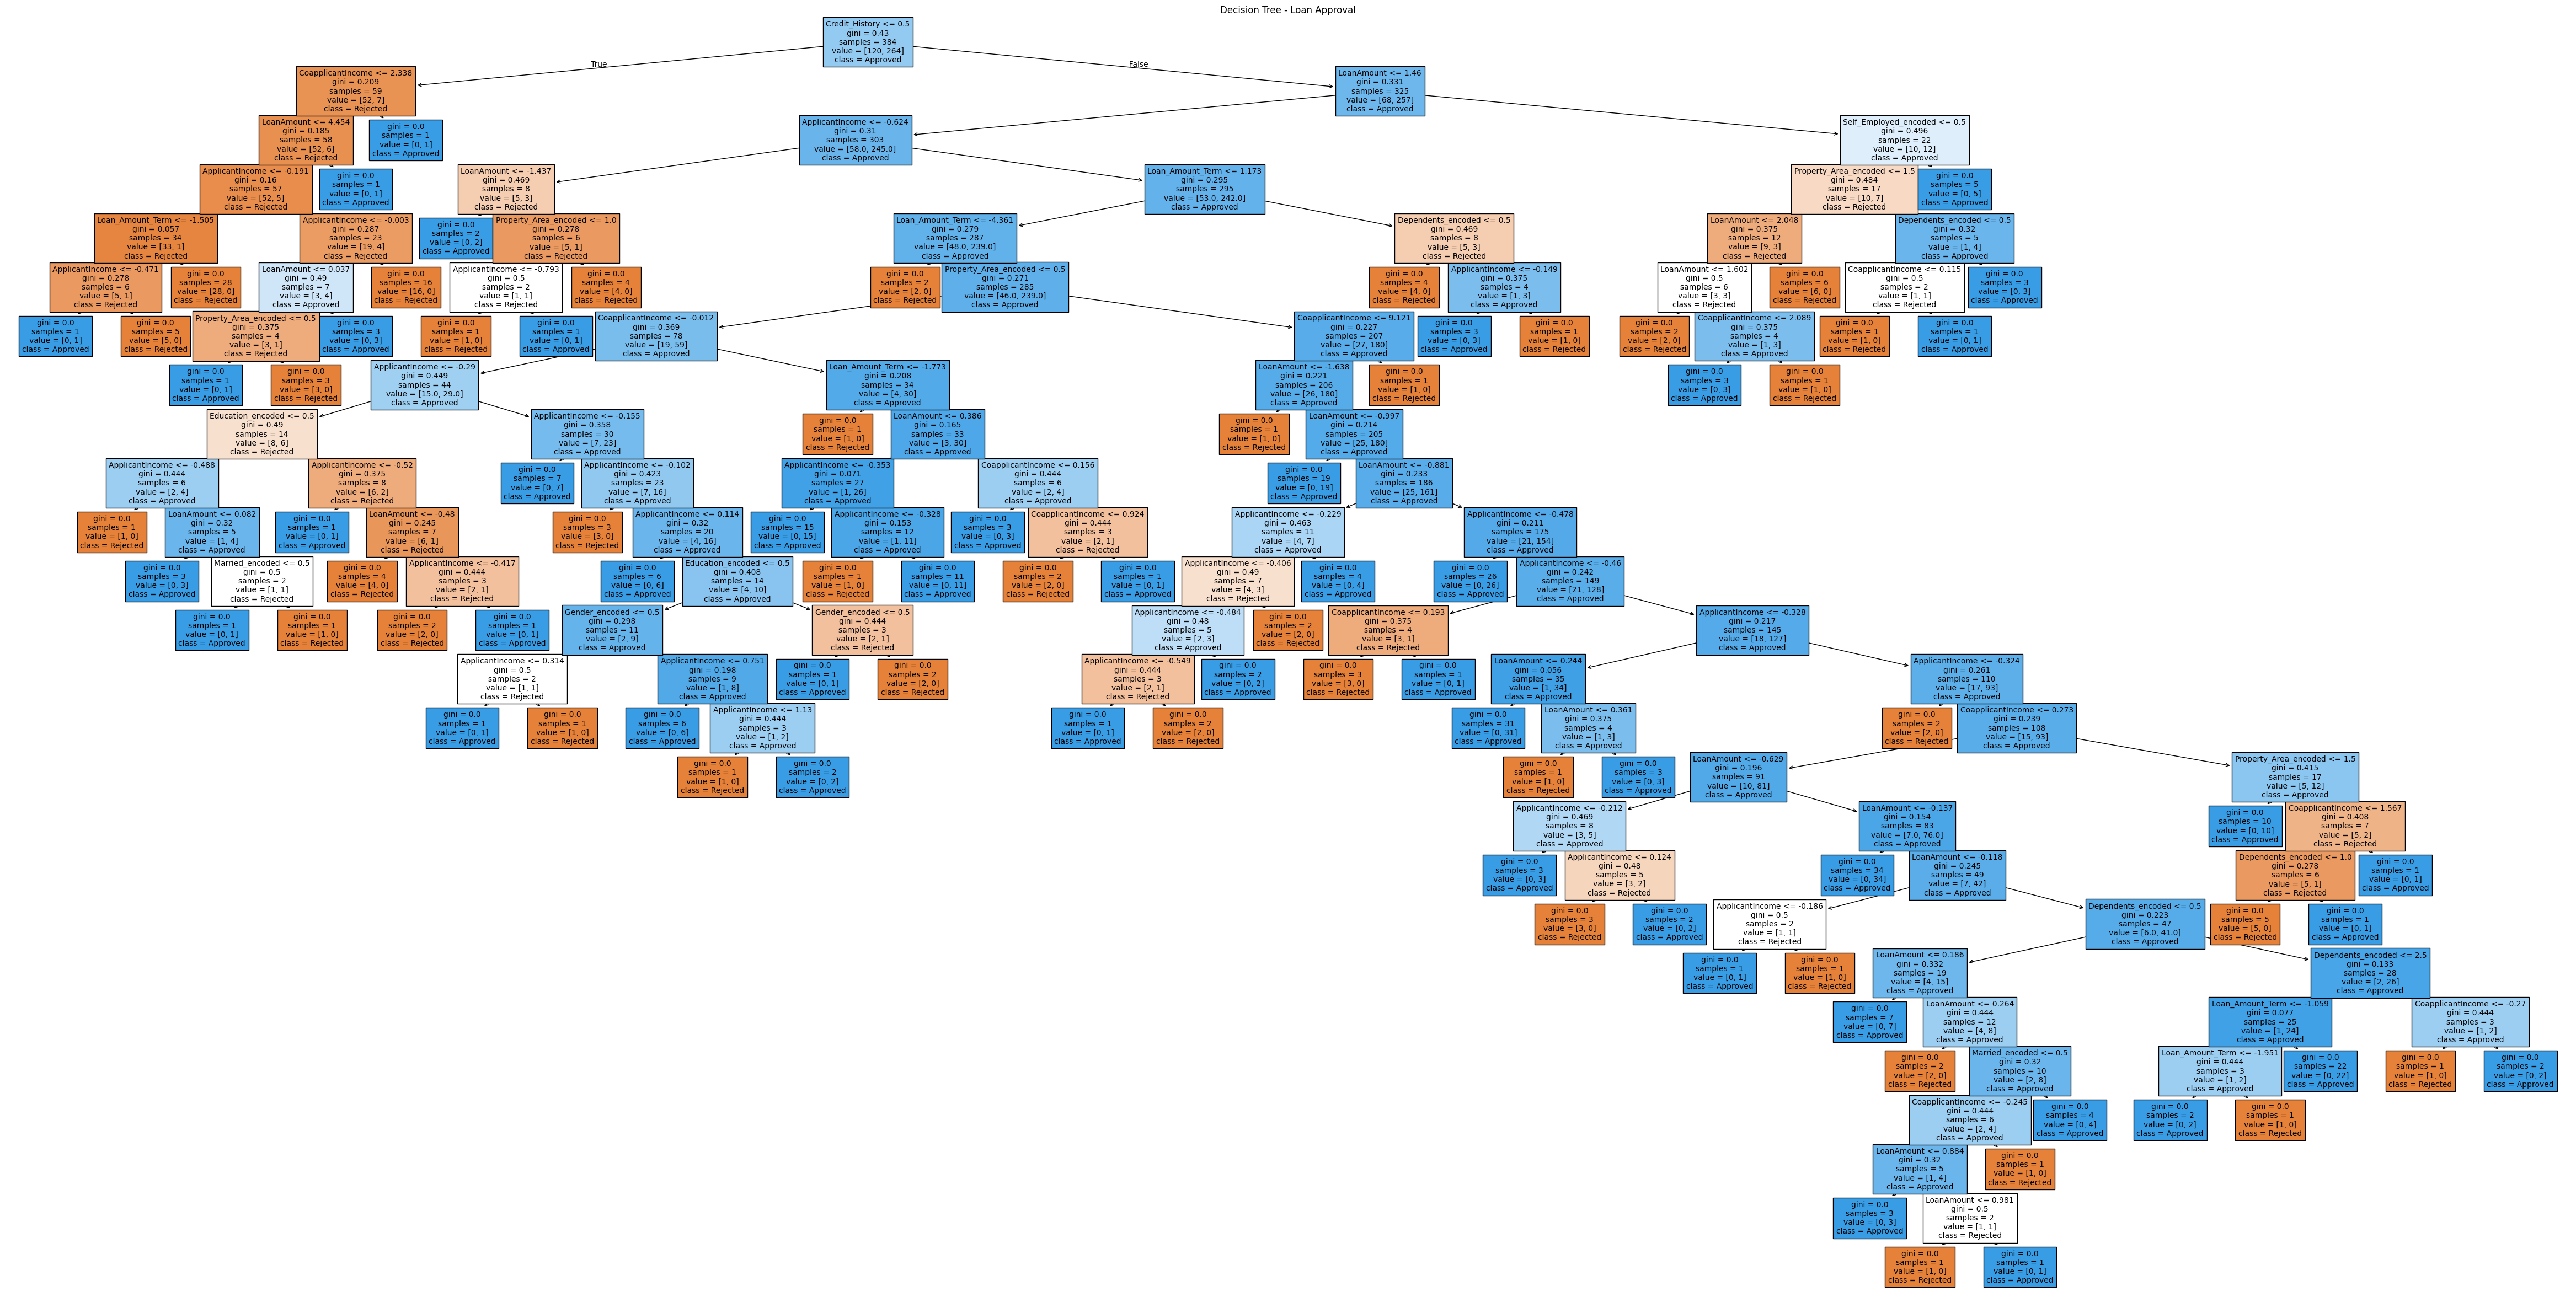

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
features = ["Gender_encoded","Married_encoded","Dependents_encoded","Education_encoded","Self_Employed_encoded","ApplicantIncome","CoapplicantIncome","LoanAmount",
    "Loan_Amount_Term","Credit_History","Property_Area_encoded"]

plt.figure(figsize=(60, 30))
plot_tree(dt,
          filled=True,
          feature_names=features,
          class_names=["Rejected", "Approved"],
          fontsize=10)
plt.title("Decision Tree - Loan Approval")
plt.savefig("decision_tree.svg", format="svg", bbox_inches="tight")
plt.show()
from google.colab import files
files.download("decision_tree.svg")

Accuracy Score: 0.8229166666666666
Precision Score: 0.8148148148148148
Recall Score: 0.9705882352941176
F1 Score: 0.8859060402684564
Confusion Matrix:
 [[13 15]
 [ 2 66]]


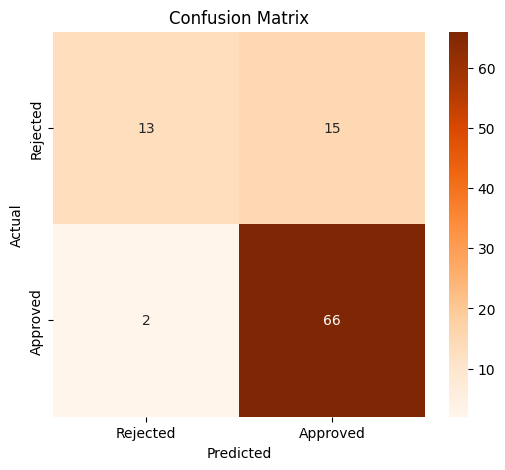

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(x_train, y_train)
y_pred__rf = rf.predict(x_test)

acc_rf = accuracy_score(y_test, y_pred__rf)
prec_rf = precision_score(y_test, y_pred__rf)
rec_rf = recall_score(y_test, y_pred__rf)
f1_rf = f1_score(y_test, y_pred__rf)

print("Accuracy Score:", acc_rf)
print("Precision Score:", prec_rf)
print("Recall Score:", rec_rf)
print("F1 Score:", f1_rf)

cm_rf = confusion_matrix(y_test, y_pred__rf)
print("Confusion Matrix:\n", cm_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Oranges",
            xticklabels=["Rejected", "Approved"],
            yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.822917,0.800000,1.000000,0.888889
1,Decision Tree,0.750000,0.814286,0.838235,0.826087
2,Random Forest,0.822917,0.814815,0.970588,0.885906


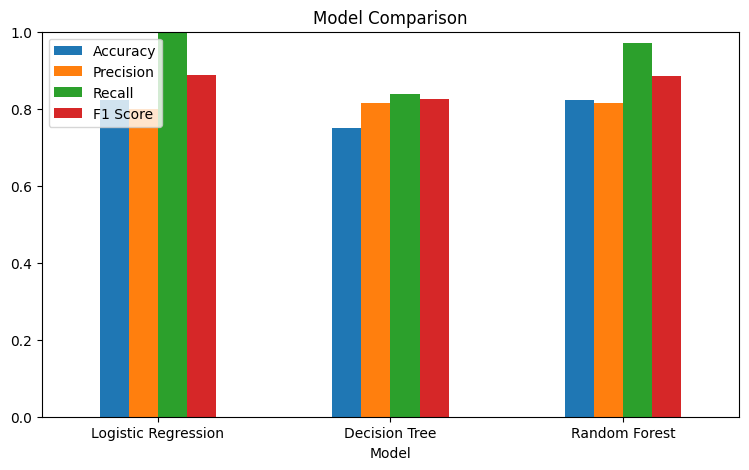

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [acc_lr, acc_dt, acc_rf],
    "Precision": [prec_lr, prec_dt, prec_rf],
    "Recall": [rec_lr, rec_dt, rec_rf],
    "F1 Score": [f1_lr, f1_dt, f1_rf]
})
display(comparison)
comparison.set_index("Model").plot(kind="bar", figsize=(9,5),ylim=(0, 1),rot=0)
plt.title("Model Comparison")
plt.legend(loc="upper left")
plt.show()